# 04. Thống kê mô tả

Phần này xem tỷ lệ hài lòng chung, thống kê tuổi, khoảng cách bay, thời gian trễ và cơ cấu hành khách.

## Đọc dữ liệu

Dùng dữ liệu sạch từ bước 03. Mở notebook trong thư mục gốc của dự án để đọc được `data/airline_clean.csv`.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/airline_clean.csv")

## Số lượng và tỷ lệ hài lòng

`value_counts()` đếm số người ở mỗi trạng thái. Thêm `normalize=True` để tính tỷ lệ trên các giá trị không thiếu, rồi nhân 100 để đổi sang phần trăm.

In [2]:
sat_count = df["satisfaction"].value_counts()
sat_rate = df["satisfaction"].value_counts(normalize=True) * 100

print("Số lượng:")
print(sat_count)
print("\nTỷ lệ (%):")
print(sat_rate.round(2))

Số lượng:
satisfaction
neutral or dissatisfied    73452
satisfied                  56428
Name: count, dtype: int64

Tỷ lệ (%):
satisfaction
neutral or dissatisfied    56.55
satisfied                  43.45
Name: proportion, dtype: float64


## Biểu đồ tỷ lệ hài lòng

Nhãn `neutral or dissatisfied` gồm cả người trung lập và người không hài lòng.

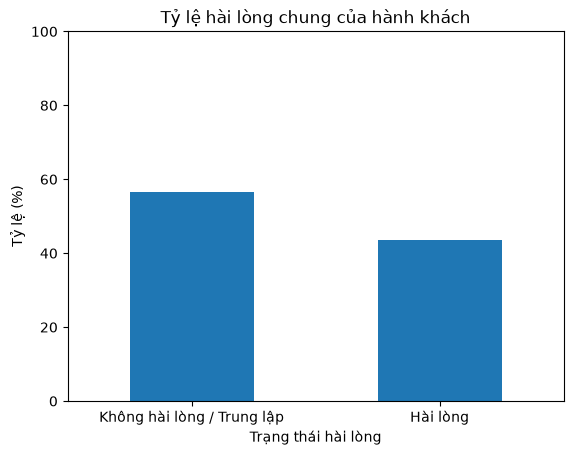

In [3]:
sat_rate.plot(kind="bar")
plt.title("Tỷ lệ hài lòng chung của hành khách")
plt.xlabel("Trạng thái hài lòng")
plt.ylabel("Tỷ lệ (%)")
plt.xticks([0, 1], ["Không hài lòng / Trung lập", "Hài lòng"], rotation=0)
plt.ylim(0, 100)
plt.show()

## Thống kê các biến số

Bảng `describe()` gồm số quan sát, trung bình, độ lệch chuẩn, giá trị nhỏ nhất, các phân vị và giá trị lớn nhất. Cột 50% là trung vị; có thể so với trung bình để xem dữ liệu có lệch nhiều không. Hai cột delay tính bằng phút.

In [4]:
num_cols = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]
print(df[num_cols].describe().T.round(2))

                               count     mean     std   min    25%    50%  \
Age                         129880.0    39.43   15.12   7.0   27.0   40.0   
Flight Distance             129880.0  1190.32  997.45  31.0  414.0  844.0   
Departure Delay in Minutes  129880.0    14.71   38.07   0.0    0.0    0.0   
Arrival Delay in Minutes    129487.0    15.09   38.47   0.0    0.0    0.0   

                               75%     max  
Age                           51.0    85.0  
Flight Distance             1744.0  4983.0  
Departure Delay in Minutes    12.0  1592.0  
Arrival Delay in Minutes      13.0  1584.0  


## Cơ cấu hành khách

Đếm số người theo giới tính, loại khách hàng, mục đích bay và hạng vé. Bảng này cho biết quy mô mỗi nhóm; tỷ lệ hài lòng theo nhóm được tính ở bài 05.

In [5]:
for col in ["Gender", "Customer Type", "Type of Travel", "Class"]:
    print("\n", col)
    print(df[col].value_counts())


 Gender
Gender
Female    65899
Male      63981
Name: count, dtype: int64

 Customer Type
Customer Type
Loyal Customer       106100
disloyal Customer     23780
Name: count, dtype: int64

 Type of Travel
Type of Travel
Business travel    89693
Personal Travel    40187
Name: count, dtype: int64

 Class
Class
Business    62160
Eco         58309
Eco Plus     9411
Name: count, dtype: int64


## Nhận xét

Trong 129.880 hành khách, có 56.428 người hài lòng, chiếm 43,45%. Còn lại 73.452 người trung lập hoặc không hài lòng, chiếm 56,55%.

Tuổi trung bình là 39,43. Cột Arrival Delay còn thiếu 393 giá trị nên thống kê chỉ tính trên 129.487 người có dữ liệu ở cột này. Nếu thay dữ liệu đầu vào, cần xem lại các con số trong nhận xét.

Các kết quả trên mô tả bộ dữ liệu Airline Passenger Satisfaction, chưa thể suy rộng cho mọi hành khách hoặc dùng để kết luận quan hệ nhân quả. Phần kiểm định nằm ở notebook 09.